In [1]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

from IPython.display import display

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Step 2: Create a sample sales dataset

np.random.seed(42)

n = 100

df = pd.DataFrame({
    "Order_ID": range(1001, 1001 + n),
    "Customer": np.random.choice(
        ["Komal", "Rahul", "Priya", "Amit", "Sneha", "Anjali"],
        n
    ),
    "City": np.random.choice(
        ["Hyderabad", "Bangalore", "Chennai", "Pune"],
        n
    ),
    "Category": np.random.choice(
        ["Electronics", "Clothing", "Furniture", "Grocery"],
        n
    ),
    "Quantity": np.random.randint(1, 6, n),
    "Sales": np.random.randint(200, 5000, n).astype(float),
    "Order_Date": pd.date_range(
        "2026-01-01", periods=n, freq="D"
    ).astype(str)
})

# Introduce missing values
df.loc[[3, 12, 25], "Customer"] = np.nan
df.loc[[5, 18, 30], "Sales"] = np.nan
df.loc[[7, 21], "City"] = np.nan

# Introduce inconsistent text formatting
df.loc[0, "City"] = " hyderabad "
df.loc[1, "Category"] = "electronics"
df.loc[2, "Category"] = "CLOTHING"

# Introduce duplicate records
df = pd.concat([df, df.iloc[[10, 20]]], ignore_index=True)

# Save the original messy dataset
df.to_csv("raw_sales_data.csv", index=False)

print("Sample dataset created successfully!")
print("Rows and columns:", df.shape)
display(df.head(10))


Sample dataset created successfully!
Rows and columns: (102, 7)


,Order_ID,Customer,City,Category,Quantity,Sales,Order_Date
0,1001,Amit,hyderabad,Grocery,5,1339.0,2026-01-01
1,1002,Sneha,Hyderabad,electronics,3,390.0,2026-01-02
2,1003,Priya,Hyderabad,CLOTHING,4,2500.0,2026-01-03
3,1004,NaN,Hyderabad,Clothing,4,1180.0,2026-01-04
4,1005,Sneha,Chennai,Furniture,3,3175.0,2026-01-05
5,1006,Rahul,Hyderabad,Grocery,4,NaN,2026-01-06
6,1007,Priya,Pune,Clothing,3,3527.0,2026-01-07
7,1008,Priya,NaN,Furniture,2,3594.0,2026-01-08
8,1009,Priya,Pune,Grocery,3,327.0,2026-01-09
9,1010,Sneha,Pune,Electronics,3,2265.0,2026-01-10


In [3]:

# Step 3: Inspect data quality

print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

print("\nStatistical summary:")
display(df.describe(include="all"))


Dataset shape: (102, 7)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    102 non-null    int64  
 1   Customer    99 non-null     object 
 2   City        100 non-null    object 
 3   Category    102 non-null    object 
 4   Quantity    102 non-null    int64  
 5   Sales       99 non-null     float64
 6   Order_Date  102 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 5.7+ KB

Missing values in each column:
Order_ID      0
Customer      3
City          2
Category      0
Quantity      0
Sales         3
Order_Date    0
dtype: int64

Number of duplicate rows:
2

Statistical summary:


,Order_ID,Customer,City,Category,Quantity,Sales,Order_Date
count,102.000000,99,100,102,102.000000,99.000000,102
unique,NaN,6,5,6,NaN,NaN,100
top,NaN,Amit,Chennai,Electronics,NaN,NaN,2026-01-21
freq,NaN,26,33,27,NaN,NaN,2
mean,1049.823529,NaN,NaN,NaN,2.950980,2615.656566,NaN
std,29.130778,NaN,NaN,NaN,1.395732,1444.518875,NaN
min,1001.000000,NaN,NaN,NaN,1.000000,204.000000,NaN
25%,1024.250000,NaN,NaN,NaN,2.000000,1310.000000,NaN
50%,1049.500000,NaN,NaN,NaN,3.000000,2737.000000,NaN
75%,1074.750000,NaN,NaN,NaN,4.000000,3905.500000,NaN


In [4]:

# Step 4: Clean and preprocess the data

# Keep a copy of the original data for comparison
raw_df = df.copy()

# 1. Remove duplicate rows
df = df.drop_duplicates().copy()

# 2. Fix text formatting
for col in ["Customer", "City", "Category"]:
    df[col] = df[col].astype("string").str.strip().str.title()

# 3. Convert Sales and Quantity into numeric values
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

# 4. Convert Order_Date to datetime
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

# 5. Fill missing customer, city, and category values
for col in ["Customer", "City", "Category"]:
    df[col] = df[col].fillna("Unknown")

# 6. Fill missing Sales with the median
df["Sales"] = df["Sales"].fillna(df["Sales"].median())

# 7. Fill missing Quantity with the median
df["Quantity"] = df["Quantity"].fillna(
    df["Quantity"].median()
)

# 8. Create a Month column for reporting
df["Month"] = df["Order_Date"].dt.to_period("M").astype(str)

# Save cleaned dataset
df.to_csv("cleaned_sales_data.csv", index=False)

print("Data cleaning completed successfully!")
display(df.head(10))


Data cleaning completed successfully!


,Order_ID,Customer,City,Category,Quantity,Sales,Order_Date,Month
0,1001,Amit,Hyderabad,Grocery,5,1339.0,2026-01-01,2026-01
1,1002,Sneha,Hyderabad,Electronics,3,390.0,2026-01-02,2026-01
2,1003,Priya,Hyderabad,Clothing,4,2500.0,2026-01-03,2026-01
3,1004,Unknown,Hyderabad,Clothing,4,1180.0,2026-01-04,2026-01
4,1005,Sneha,Chennai,Furniture,3,3175.0,2026-01-05,2026-01
5,1006,Rahul,Hyderabad,Grocery,4,2860.0,2026-01-06,2026-01
6,1007,Priya,Pune,Clothing,3,3527.0,2026-01-07,2026-01
7,1008,Priya,Unknown,Furniture,2,3594.0,2026-01-08,2026-01
8,1009,Priya,Pune,Grocery,3,327.0,2026-01-09,2026-01
9,1010,Sneha,Pune,Electronics,3,2265.0,2026-01-10,2026-01


In [5]:

# Step 5: Check cleaned data quality

print("Original number of rows:", len(raw_df))
print("Rows after cleaning:", len(df))
print("Duplicate rows remaining:", df.duplicated().sum())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nCleaned data types:")
print(df.dtypes)

print("\nCleaning verification completed!")


Original number of rows: 102
Rows after cleaning: 100
Duplicate rows remaining: 0

Missing values after cleaning:
Order_ID      0
Customer      0
City          0
Category      0
Quantity      0
Sales         0
Order_Date    0
Month         0
dtype: int64

Cleaned data types:
Order_ID               int64
Customer      string[python]
City          string[python]
Category      string[python]
Quantity               int64
Sales                float64
Order_Date    datetime64[ns]
Month                 object
dtype: object

Cleaning verification completed!


In [6]:

# Step 6: Generate summary reports

total_sales = df["Sales"].sum()
total_quantity = df["Quantity"].sum()
total_orders = len(df)
average_sales = df["Sales"].mean()

category_report = (
    df.groupby("Category", as_index=False)
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Number_of_Orders=("Order_ID", "count")
      )
      .sort_values("Total_Sales", ascending=False)
)

city_report = (
    df.groupby("City", as_index=False)
      .agg(
          Total_Sales=("Sales", "sum"),
          Number_of_Orders=("Order_ID", "count")
      )
      .sort_values("Total_Sales", ascending=False)
)

monthly_report = (
    df.groupby("Month", as_index=False)
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Quantity=("Quantity", "sum")
      )
)

print("AUTOMATED SALES REPORT")
print("----------------------")
print(f"Total orders: {total_orders}")
print(f"Total sales: {total_sales:.2f}")
print(f"Total quantity sold: {total_quantity}")
print(f"Average sales per row: {average_sales:.2f}")

print("\nCategory-wise report:")
display(category_report)

print("\nCity-wise report:")
display(city_report)

print("\nMonthly report:")
display(monthly_report)


AUTOMATED SALES REPORT
----------------------
Total orders: 100
Total sales: 265160.00
Total quantity sold: 295
Average sales per row: 2651.60

Category-wise report:


,Category,Total_Sales,Total_Quantity,Number_of_Orders
3,Grocery,72917.0,77,26
2,Furniture,70775.0,65,23
1,Electronics,66944.0,73,27
0,Clothing,54524.0,80,24



City-wise report:


,City,Total_Sales,Number_of_Orders
1,Chennai,98414.0,33
3,Pune,61582.0,23
2,Hyderabad,49814.0,27
0,Bangalore,49019.0,15
4,Unknown,6331.0,2



Monthly report:


,Month,Total_Sales,Total_Quantity
0,2026-01,77839.0,82
1,2026-02,81567.0,81
2,2026-03,76911.0,96
3,2026-04,28843.0,36


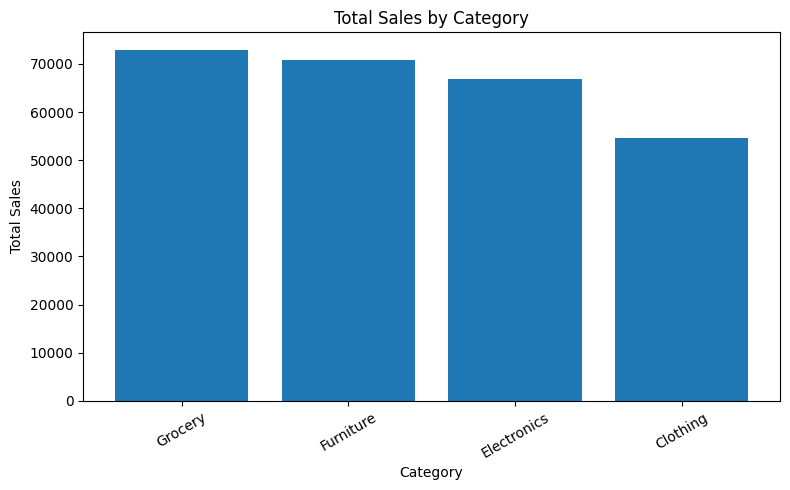

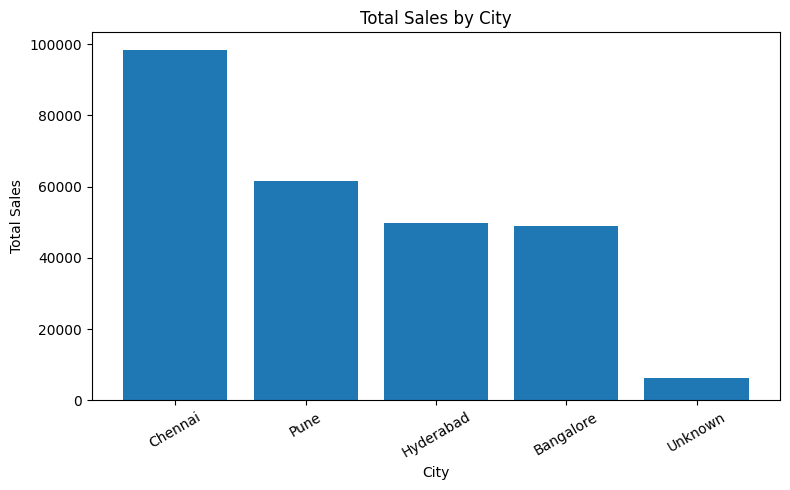

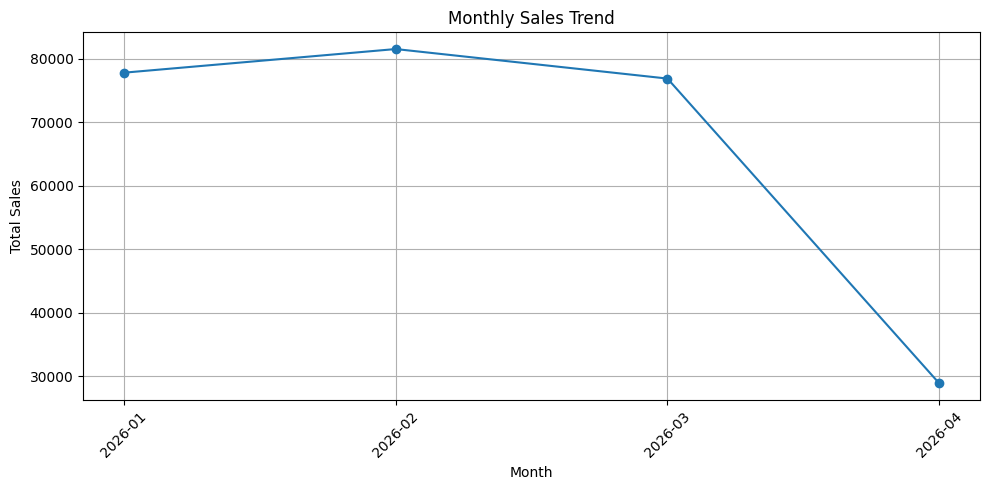

All charts created and saved successfully!


In [7]:

# Step 7: Create and save visual summaries

os.makedirs("charts", exist_ok=True)

# Chart 1: Sales by category
plt.figure(figsize=(8, 5))
plt.bar(category_report["Category"], category_report["Total_Sales"])
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("charts/sales_by_category.png", dpi=150)
plt.show()

# Chart 2: Sales by city
plt.figure(figsize=(8, 5))
plt.bar(city_report["City"], city_report["Total_Sales"])
plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("charts/sales_by_city.png", dpi=150)
plt.show()

# Chart 3: Monthly sales
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_report["Month"],
    monthly_report["Total_Sales"],
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("charts/monthly_sales_trend.png", dpi=150)
plt.show()

print("All charts created and saved successfully!")


In [8]:

# Step 8: Export all reports to Excel

with pd.ExcelWriter("Automated_Sales_Report.xlsx") as writer:
    raw_df.to_excel(
        writer, sheet_name="Raw_Data", index=False
    )
    df.to_excel(
        writer, sheet_name="Cleaned_Data", index=False
    )
    category_report.to_excel(
        writer, sheet_name="Category_Report", index=False
    )
    city_report.to_excel(
        writer, sheet_name="City_Report", index=False
    )
    monthly_report.to_excel(
        writer, sheet_name="Monthly_Report", index=False
    )

print("Excel report generated successfully!")


Excel report generated successfully!


In [9]:

# Step 9: Generate an automated text report

report_text = f"""
DATA CLEANING AND REPORTING AUTOMATION
======================================

PROJECT SUMMARY
---------------
Original rows: {len(raw_df)}
Cleaned rows: {len(df)}
Duplicate rows removed: {len(raw_df) - len(raw_df.drop_duplicates())}
Missing values remaining: {int(df.isnull().sum().sum())}

SALES SUMMARY
-------------
Total orders (rows): {len(df)}
Total sales: {total_sales:.2f}
Total quantity sold: {total_quantity}
Average sales per row: {average_sales:.2f}

TOP PERFORMING CATEGORY
-----------------------
{category_report.iloc[0]["Category"]}

TOP PERFORMING CITY
-------------------
{city_report.iloc[0]["City"]}

FILES GENERATED
---------------
raw_sales_data.csv
cleaned_sales_data.csv
Automated_Sales_Report.xlsx
charts/sales_by_category.png
charts/sales_by_city.png
charts/monthly_sales_trend.png

CONCLUSION
----------
The workflow cleaned the sales dataset, removed duplicate rows,
handled missing values, standardized text fields, and generated
automated summary reports and charts.
"""

with open("Automated_Report.txt", "w", encoding="utf-8") as f:
    f.write(report_text)

print(report_text)



DATA CLEANING AND REPORTING AUTOMATION

PROJECT SUMMARY
---------------
Original rows: 102
Cleaned rows: 100
Duplicate rows removed: 2
Missing values remaining: 0

SALES SUMMARY
-------------
Total orders (rows): 100
Total sales: 265160.00
Total quantity sold: 295
Average sales per row: 2651.60

TOP PERFORMING CATEGORY
-----------------------
Grocery

TOP PERFORMING CITY
-------------------
Chennai

FILES GENERATED
---------------
raw_sales_data.csv
cleaned_sales_data.csv
Automated_Sales_Report.xlsx
charts/sales_by_category.png
charts/sales_by_city.png
charts/monthly_sales_trend.png

CONCLUSION
----------
The workflow cleaned the sales dataset, removed duplicate rows,
handled missing values, standardized text fields, and generated
automated summary reports and charts.



In [10]:

# Step 10: Package deliverables into a ZIP file

files_to_include = [
    "raw_sales_data.csv",
    "cleaned_sales_data.csv",
    "Automated_Sales_Report.xlsx",
    "Automated_Report.txt",
    "charts/sales_by_category.png",
    "charts/sales_by_city.png",
    "charts/monthly_sales_trend.png"
]

with zipfile.ZipFile(
    "Data_Cleaning_Reporting_Submission.zip", "w"
) as zipf:
    for file in files_to_include:
        zipf.write(file)

print("Submission ZIP created successfully!")
print("File: Data_Cleaning_Reporting_Submission.zip")


Submission ZIP created successfully!
File: Data_Cleaning_Reporting_Submission.zip


In [11]:

from google.colab import files

files.download("Data_Cleaning_Reporting_Submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>